# Segmentación y perfiles socioeducativos

In [1]:
from pathlib import Path
import sys, json
import pandas as pd
from IPython.display import display, Image, Markdown
from threadpoolctl import threadpool_limits
ROOT=Path.cwd()
if not (ROOT/'src').is_dir(): ROOT=ROOT.parent
sys.path.insert(0,str(ROOT/'src'))
from scientific_audit import evaluate, sha
pd.set_option('display.precision',9)
def audit(phase):
    with threadpool_limits(limits=4): record=evaluate(phase)
    display(pd.DataFrame(record['checks']))
    print('Controles ejecutados:',len(record['checks']),'| Estado:',record['status'])
    print(record['historical_test_warning'])
    return record['detail']
def table(name): display(pd.read_csv(ROOT/'reports/tables'/name))
def figure(name):
    path=ROOT/'reports/figures'/name
    print('Figura:',name,'| SHA-256:',sha(path))
    display(Image(filename=str(path)))
print('Evaluación real de artefactos guardados; no se entrenan clasificadores.')


Evaluación real de artefactos guardados; no se entrenan clasificadores.


## Método y alcance

Se evalúa el GMM guardado de dos componentes. Se recalculan asignaciones, silueta en 2 500 casos con semilla 42, Davies–Bouldin y Calinski–Harabasz en desarrollo; se contrastan tamaños y tasas ponderadas. La etiqueta no interviene en el ajuste ni la selección. La comparación completa y la ablación se contrastan también mediante entrenamiento aislado.

${PROJECT_ROOT}/.venv/lib/python3.12/site-packages/tqdm/auto.py:21: TqdmWarning: IProgress not found. Please update jupyter and ipywidgets. See https://ipywidgets.readthedocs.io/en/stable/user_install.html
  from .autonotebook import tqdm as notebook_tqdm


,name,passed
0,saved_gmm_k2,True
1,train_assignments,True
2,test_assignments,True
3,geometry_silueta,True
4,geometry_davies_bouldin,True
5,geometry_calinski_harabasz,True
6,imputer_development_only,True
7,profile_size_0,True
8,profile_nonuse_0,True
9,profile_size_1,True


Controles ejecutados: 11 | Estado: passed
La partición de prueba ya se inspeccionó en la versión anterior. Se conserva para comparabilidad, sin usarla para selección nueva; esta auditoría es retrospectiva y no aporta una prueba externa inédita.


,metodo,k,silueta,davies_bouldin,calinski_harabasz
0,GMM,2,0.453928052,1.452377688,3037.70139701


Ablación: {'features': ['log_ingreso_pc', 'log_gasto_pc', 'altitud', 'ratio_alumnos_docente', 'prop_publicas'], 'silueta': 0.27913214200381065, 'ari_vs_completo': 0.08075259236459058, 'note': 'Mismo metodo y k sin electricidad/internet; diagnostico de dependencia de acceso, no nueva seleccion por etiqueta.'}


,metodo,k,silueta,davies_bouldin,calinski_harabasz,min_proporcion,elegible
0,KMeans,2,0.323305324,1.397657792,5337.305215201,0.379473483,True
1,KMeans,3,0.340767961,1.148999119,4925.559537406,0.040976726,False
2,KMeans,4,0.359772630,0.994546183,4980.049849711,0.040976726,False
3,KMeans,5,0.278875027,1.148662969,5110.992737901,0.040976726,False
4,KMeans,6,0.274484612,1.140055651,4964.759806459,0.040900420,False
5,GMM,2,0.453928052,1.452377688,3037.701397010,0.096985883,True
6,GMM,3,0.458154061,1.018345301,2407.406842822,0.024494468,False
7,GMM,4,0.284158605,1.168781170,3621.382092528,0.024494468,False
8,GMM,5,0.223463708,1.473965873,3725.815201730,0.040976726,False
9,GMM,6,0.228435185,1.386974606,3266.700689176,0.016482259,False


,cluster,n,proporcion,no_uso_ponderado,edad,rural,internet_hogar,electricidad,ingreso_pc_mensual,gasto_pc_mensual,altitud,ratio_alumnos_docente,prop_publicas,prop_pobreza,prop_castellano,perfil
0,0,1271,0.096985883,0.477435211,11.126418825,0.589310262,0.486262323,0.403425685,486.282471057,474.033284275,1411.204470494,13.478031220,0.773488063,0.465266448,0.815370738,Menor conectividad; rural
1,1,11834,0.903014117,0.210705478,11.545063077,0.182562994,1.000000000,1.000000000,853.471358713,704.691679573,1170.147263942,15.922128688,0.539919143,0.307014186,0.955153026,Mayor conectividad; urbano


,seed,tipo,ari_vs_seleccion
0,42,semilla,1.0
1,42,submuestra80,1.0
2,43,semilla,1.0
3,43,submuestra80,1.0
4,44,semilla,1.0
5,44,submuestra80,1.0


Figura: clustering.png | SHA-256: 81eb45326e4812a5edb94ca9fd24e017b83fef59be17ef8655b1c71887449bac


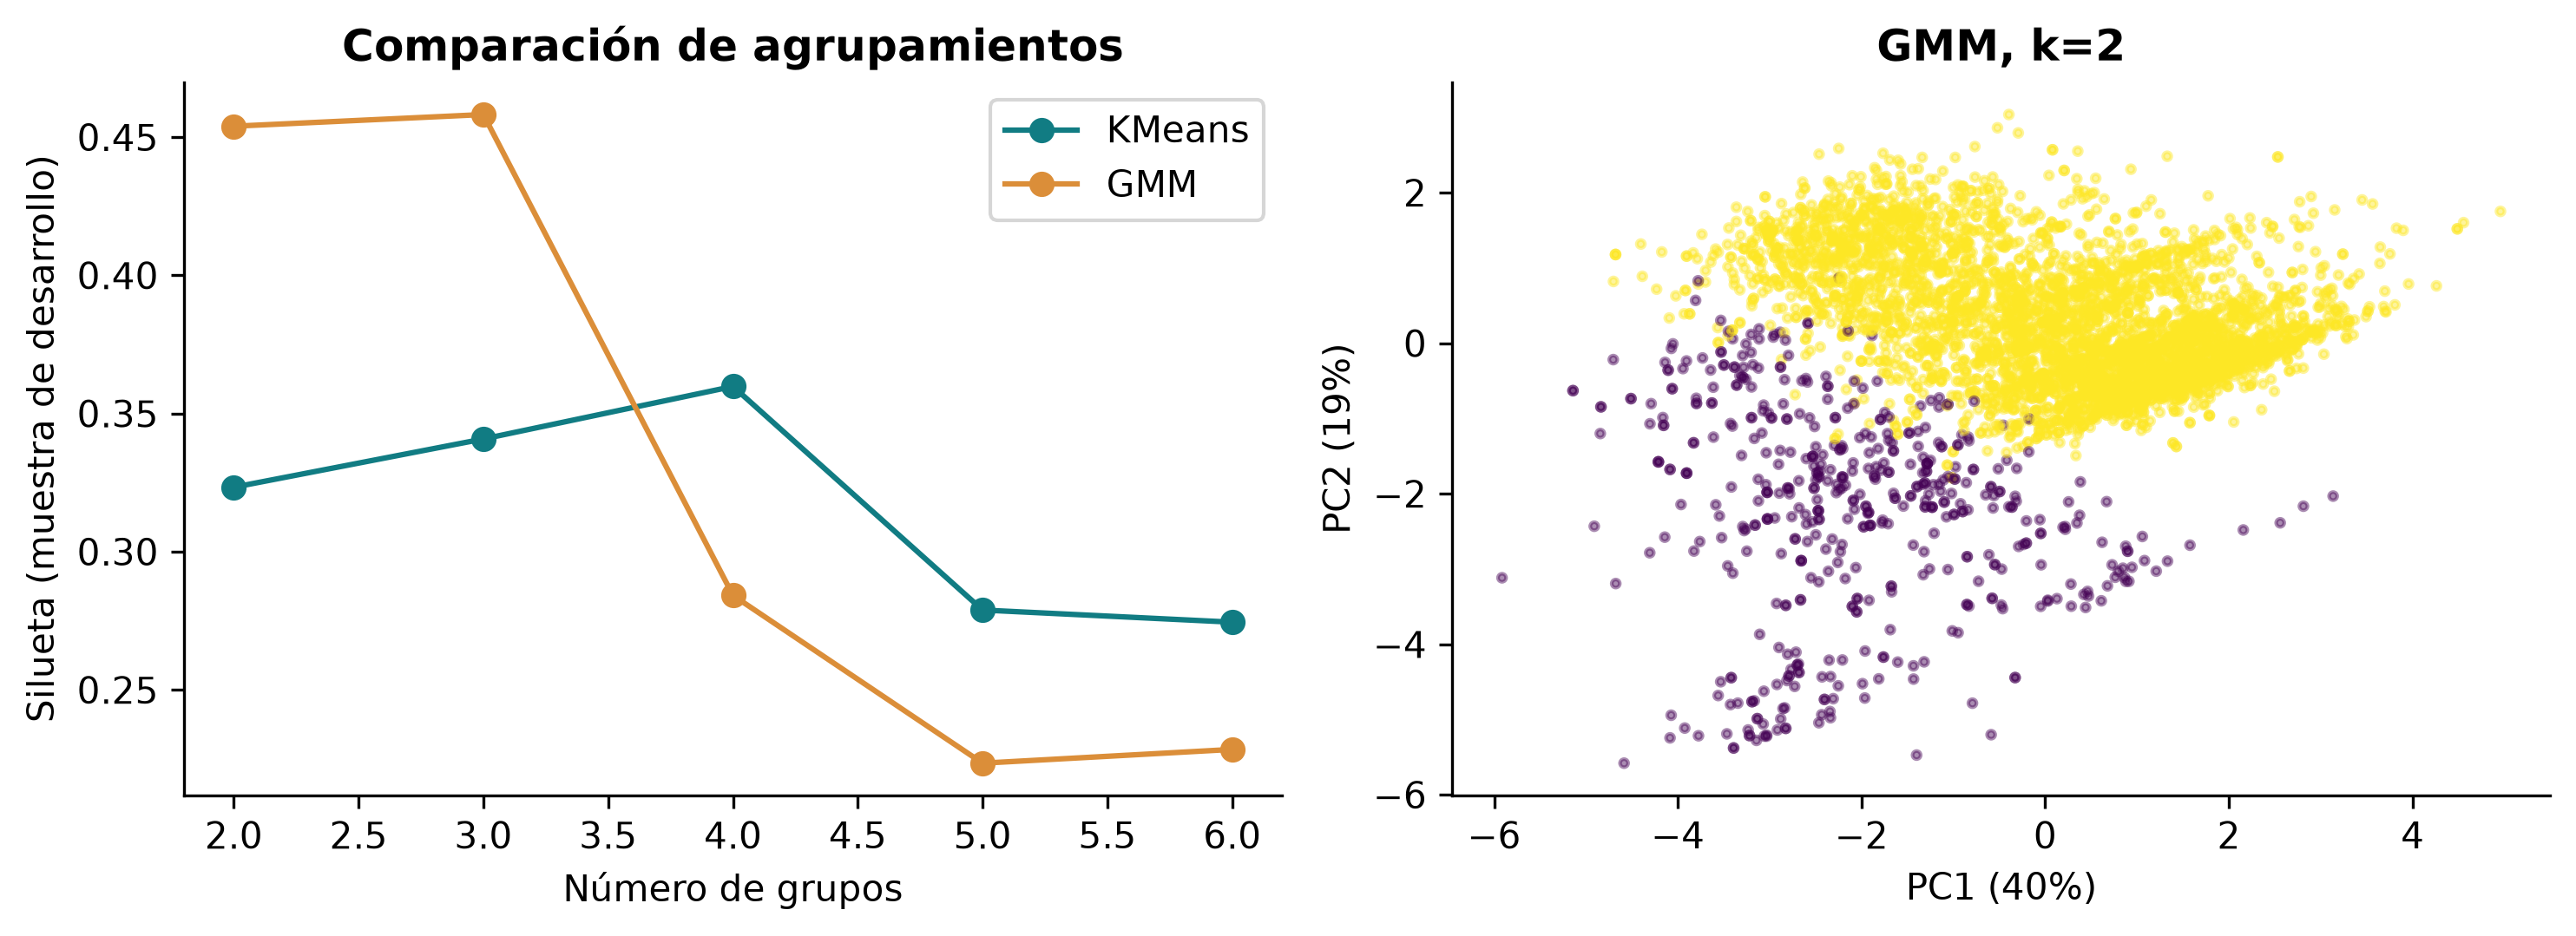

Figura: silhouette.png | SHA-256: dde5034f59f3f92b54f29dcaf734af7ad333d8273fe9040c60f44fc231bceda8


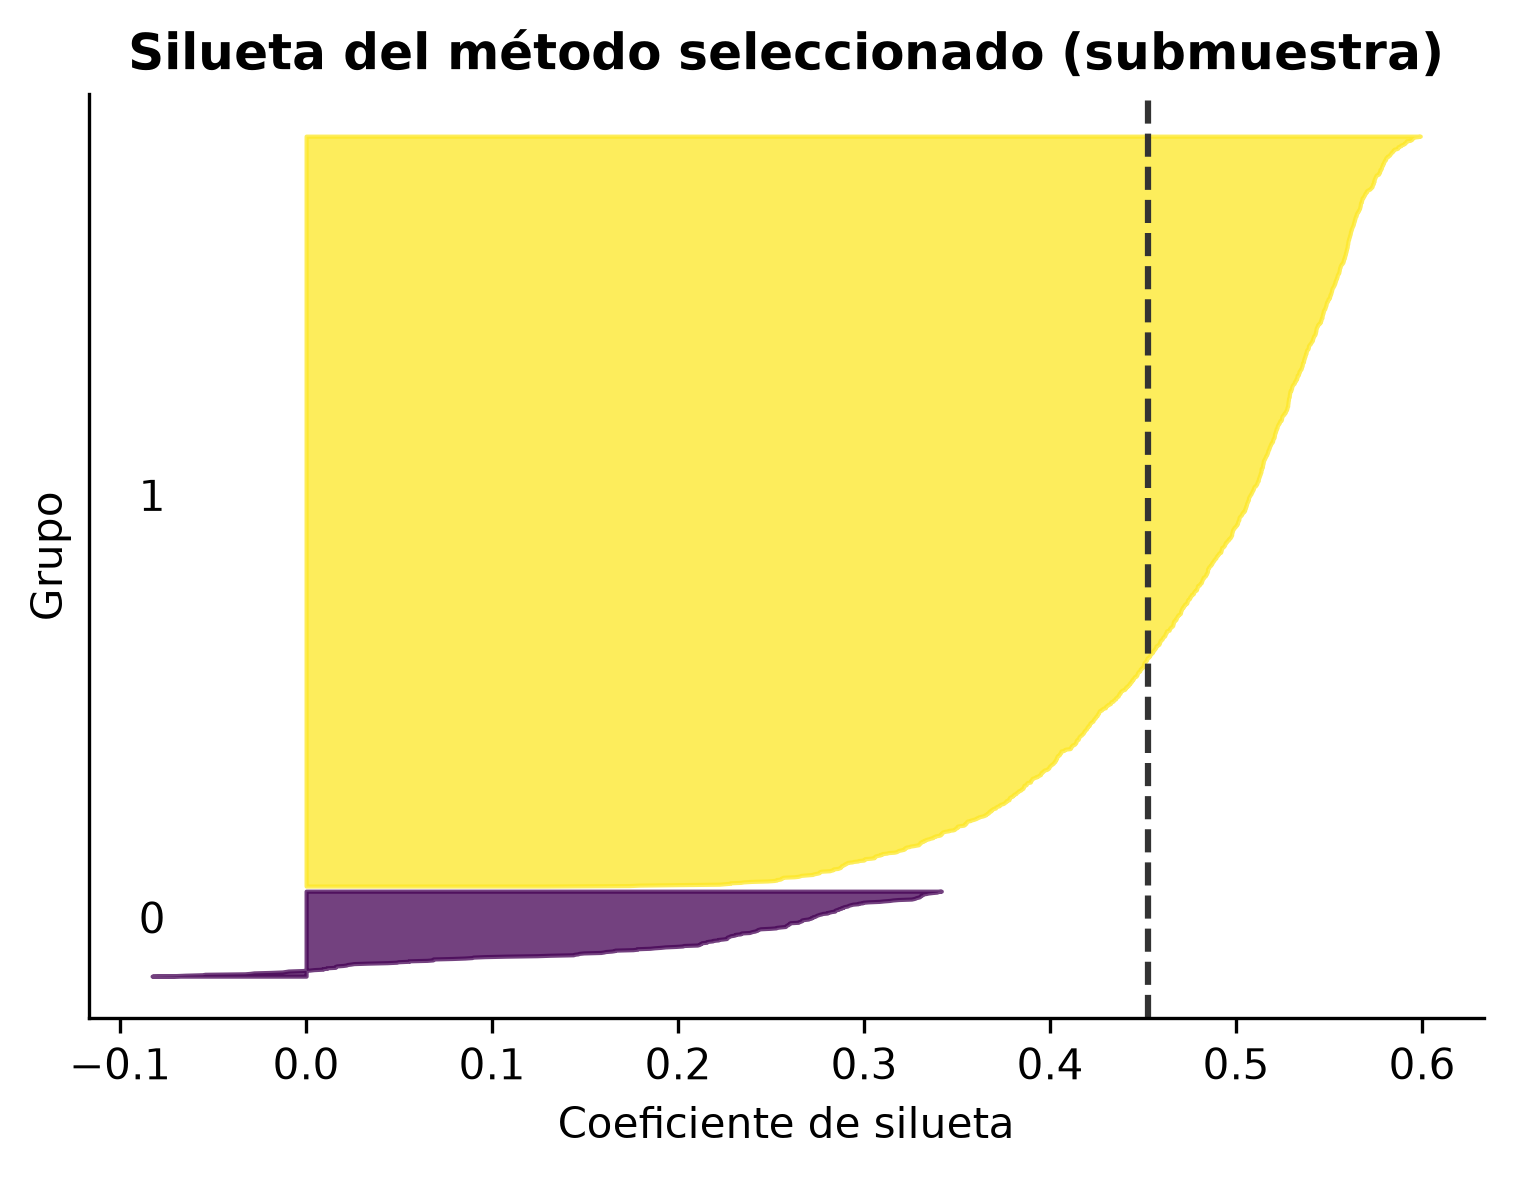

In [2]:
detail=audit('clustering')
display(pd.DataFrame([detail['selected']]))
print('Ablación:',detail['access_ablation'])
table('clustering_comparison.csv')
table('cluster_profiles.csv')
table('clustering_stability.csv')
figure('clustering.png')
figure('silhouette.png')